## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

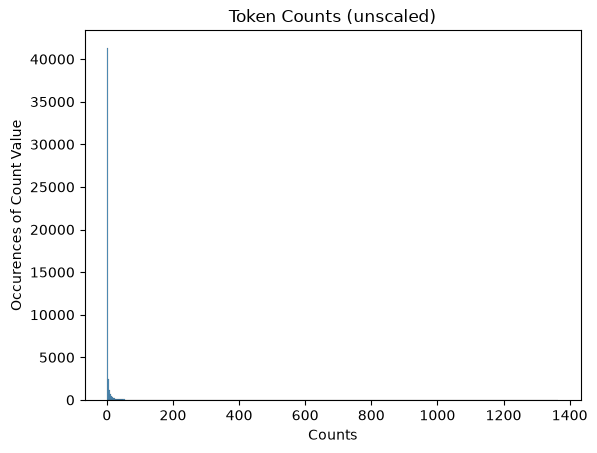

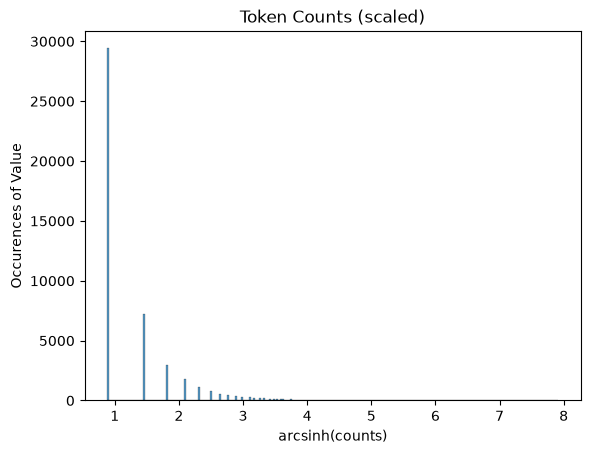

In [2]:
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()



ax = sns.histplot(data = token_count)
ax.set(title = "Token Counts (unscaled)", xlabel = "Counts", ylabel = "Occurences of Count Value")
plt.show()

scaled_counts = np.arcsinh(list(token_count.values()))
ax = sns.histplot(data = scaled_counts)
ax.set(title = "Token Counts (scaled)", xlabel = "arcsinh(counts)", ylabel = "Occurences of Value")
plt.show()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

A:
There are approximately 40,000 words in the smallest bin, and funcitonally zero in the highest. The historgram is very very heavily left-skewed and right-tailed. In context, this tells us that there are tens of thousands of instances of low-count words, and few instances of very high-count words.

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("data/Phishing_clean.parquet")

y = df["Email Type"]
x = df.drop(columns = "Email Type")

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 65)

model = LinearRegression().fit(x_train, y_train)
print("R^2 on the training set was", model.score(x_train, y_train))
print("R^2 on the test set was", model.score(x_test, y_test))


coef_df = pd.DataFrame({"word": x_train.columns, "coef": model.coef_})
coef_df["abs_coef"] = np.abs(coef_df["coef"])
coef_df.sort_values("abs_coef", ascending=False).head(10)



R^2 on the training set was 0.7677733084118992
R^2 on the test set was 0.6571173475409766


,word,coef,abs_coef
906,aging,0.996514,0.996514
1406,"helvetica,",0.892177,0.892177
740,localized,0.787934,0.787934
1504,background-image:,-0.780070,0.780070
2362,thermal,0.671019,0.671019
2058,12px;,0.629280,0.629280
2365,rcs,0.553536,0.553536
1810,exercise!,0.542180,0.542180
1511,burning,-0.515023,0.515023
2094,#000000;,0.502902,0.502902


**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

[[-0.01000804 -0.07596613]
 [-0.02285951 -0.00574845]
 [-0.04473029  0.44000285]
 ...
 [-0.09730272 -0.19893468]
 [-0.25035732 -0.54694182]
 [-0.00603615 -0.12900883]] 
 
 [0.01113088 0.00861244]


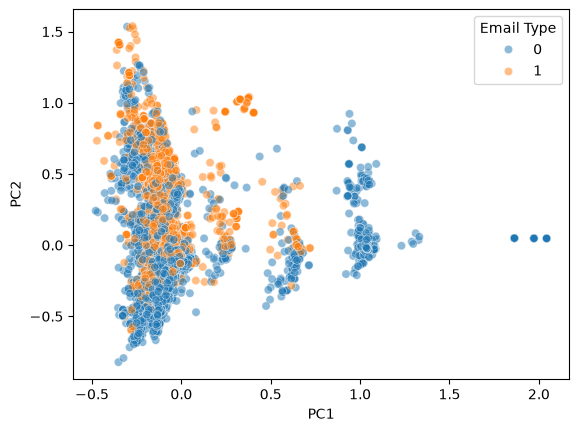

In [4]:
#Using scikit-learn PCA function from slides

from sklearn.decomposition import PCA

PCA_two = PCA(n_components=2).fit(x)
results = PCA_two.transform(x)

print(results,"\n \n", PCA_two.explained_variance_ratio_)

pc = pd.DataFrame(results, columns=["PC1", "PC2"])
pc["Email Type"] = y
sns.scatterplot(data=pc, x="PC1", y="PC2", hue="Email Type", alpha=0.5)
plt.show()


#The main takeaway I have from this graph is how had it is to differentiate between phishing and authentic
#emails. There are a few clusters of pure-blue or pure-orange, but generally, they're pretty indistinguishable.
#I printed out the variance ratio suggests that PC1 and PC2 only combine to a little under .02, which means
#that they're really not accounting for much differentiation.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [ ]:
#Check what we're working with:
print(x.shape)
print(x_train.shape)

mean_train = x_train.mean()
Z_train = x_train - mean_train
C = (Z_train.T @ Z_train) / (len(Z_train) - 1)

eigenvalues, eigenvectors = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]       # the line I left out
eigenvectors = eigenvectors[:, order]
P = eigenvectors[:, :2610]
z_train = Z_train @ P
z_test = (x_test - mean_train) @ P


pc_model = LinearRegression().fit(z_train, y_train)
r2_train = pc_model.score(z_train, y_train)
r2_test = pc_model.score(z_test, y_test)

print(r2_train, r2_test)

ratio = eigenvalues / eigenvalues.sum()
print(ratio[:2610].sum())

#The testing and training R^2s [(.766, .661) after, (.768, .657) before] are quite similar. Dropping
# 2711-2610 = 101 observations barely changed everything, since the variance ratio is 0.9999. In other
#words, they're functionally identical. Not sure if that's the right answer, though...

(18634, 2711)
(14907, 2711)
0.7668967611277832 0.6613559301353323
0.999850478591967
0.7668967611277832 0.6613559301353323


: 

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

PCA is beneficial for a few reasons, even despite the fact that I didn't really see a stark improvement in my data variance. For one, I was able to show that it can effectively reduce dimensions while still keeping variation, since the ratio came out to be 0.9999. It also keeps individual PC scores siloed off from one another, which I remember being an issue in the linear models issue (basement vs house square footage analogy). Though it has its advantages for regression, I can't really wholeheartedly pitch it as being better, since my results were nearly identical. I can confirm that it doesn't substantively worsen data, and because there are some built-in protections, I think it's advantageous.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Noah Weinstein

**Date:** 8/22/26

In [ ]:
# Your Phase 1 solution to the problem goes here.

#Sorry I did it above on accident I didn't realize

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [8a04d82]
- **AI tool and model used:** [Gemini Flash 3.6]

### *Prompts used

1. Look at Questions 1-5 in the text instructions, and my code solutions for it. Suggest 2 changes you think I should make to better address the prompt(s).
2. Elaborate on the logistic vs linear regression, please. What does logistic do that linear cannot, and how did it affect this assignment?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Change the Regression Model in Q2 to Logistic Regression
2. Add a Scatter Plot and Interpretation for PCA in Q3

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Reject | I don't remember us covering logistic regression in this class, so introducing it here would be a little strange. I asked a follow-up to learn a little more about why Claude thought I should use it, and I wasn't completely convinced. |
| 2 | Reject | Gemini's full suggestion was almost verbatim the code I already had in Part 1. I think it literally didn't even read mine, which is super weird and annoying. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

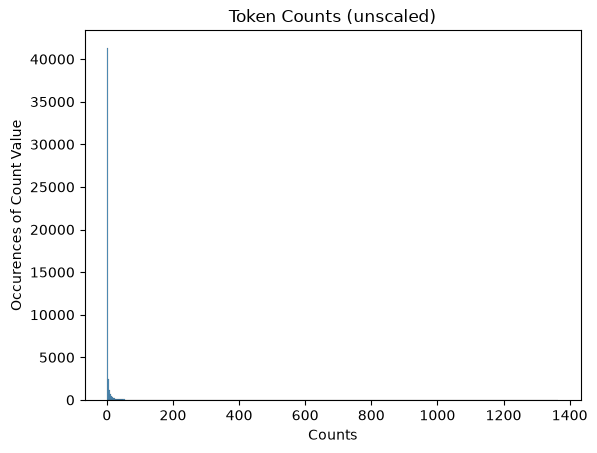

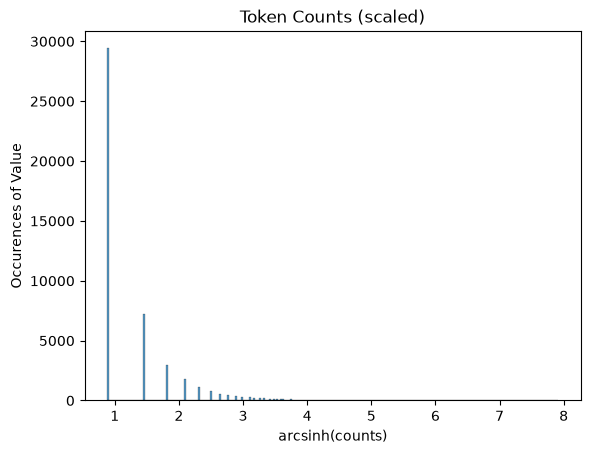

R^2 on the training set was 0.7677733084118992
R^2 on the test set was 0.6571173475409766
[[-0.01013347 -0.07719219]
 [-0.02288522 -0.00768173]
 [-0.044854    0.43903216]
 ...
 [-0.09690255 -0.1993203 ]
 [-0.25074054 -0.54267184]
 [-0.00615668 -0.13264274]] 
 
 [0.01113089 0.00861181]


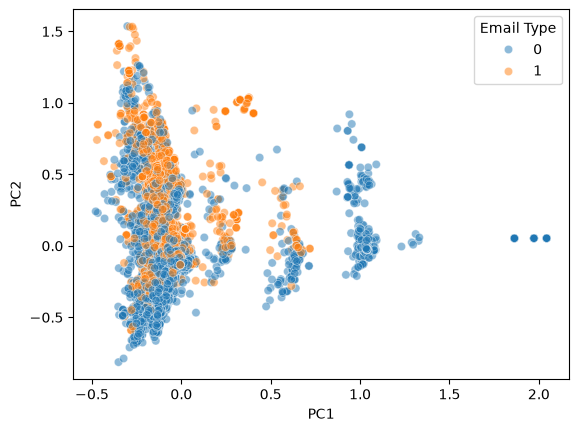

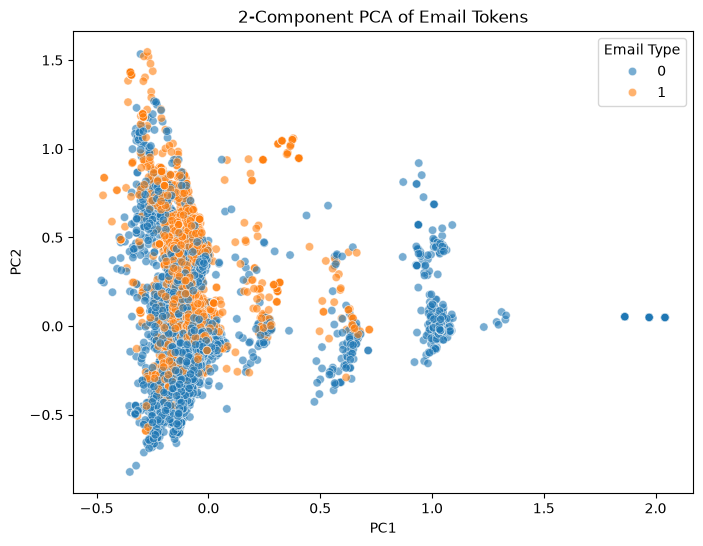

: 

In [ ]:
#Q1
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()



ax = sns.histplot(data = token_count)
ax.set(title = "Token Counts (unscaled)", xlabel = "Counts", ylabel = "Occurences of Count Value")
plt.show()

scaled_counts = np.arcsinh(list(token_count.values()))
ax = sns.histplot(data = scaled_counts)
ax.set(title = "Token Counts (scaled)", xlabel = "arcsinh(counts)", ylabel = "Occurences of Value")
plt.show()

#Q2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("data/Phishing_clean.parquet")

y = df["Email Type"]
x = df.drop(columns = "Email Type")

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 65)

model = LinearRegression().fit(x_train, y_train)
print("R^2 on the training set was", model.score(x_train, y_train))
print("R^2 on the test set was", model.score(x_test, y_test))


coef_df = pd.DataFrame({"word": x_train.columns, "coef": model.coef_})
coef_df["abs_coef"] = np.abs(coef_df["coef"])
coef_df.sort_values("abs_coef", ascending=False).head(10)


#Q3
from sklearn.decomposition import PCA

PCA_two = PCA(n_components=2).fit(x)
results = PCA_two.transform(x)

print(results,"\n \n", PCA_two.explained_variance_ratio_)

pc = pd.DataFrame(results, columns=["PC1", "PC2"])
pc["Email Type"] = y
sns.scatterplot(data=pc, x="PC1", y="PC2", hue="Email Type", alpha=0.5)
plt.show()



#Q4
mean_train = x_train.mean()
Z_train = x_train - mean_train
C = (Z_train.T @ Z_train) / (len(Z_train) - 1)

eigenvalues, eigenvectors = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]       # the line I left out
eigenvectors = eigenvectors[:, order]
P = eigenvectors[:, :2610]
z_train = Z_train @ P
z_test = (x_test - mean_train) @ P


pc_model = LinearRegression().fit(z_train, y_train)
r2_train = pc_model.score(z_train, y_train)
r2_test = pc_model.score(z_test, y_test)

print(r2_train, r2_test)

ratio = eigenvalues / eigenvalues.sum()
print(ratio[:2610].sum())

### *Reflection on AI assistance
In your own words without generative AI.

Once again, I'm pretty disappointed with Gemini's performance as my evaluator. I'd been leaning towards Gemini because I have the free usage plan through my student email, but it's gotten bad to the point where I don't think it's at all helpful for my coding improvement anymore. I can't fault it for its faulty first suggestion, because it may not have known that I'm a student coder who doesn't inherently know everything, but the second one was pretty negligent. I don't understand how it went into my notebook and made a suggestion I didn't need. In all honesty, I was hoping for more support on this -- my kernels have been crashing, and I was really expecting it to give me a scathing, but helpful, code review. I feel disheartened and unconfident in AI's ability to catch my mistakes, which is a shame because I'm a pretty amateur coder. In my personal life, I've tried using Gen AI to code, and I feel as though it either goes way over my head or dumbs it down too much (like here, where it's pretty much useless).